[*********************100%***********************]  1 of 1 completed
c:\Users\sreeh\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,651 (119.73 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 12s 57ms/step - loss: 0.0104
Epoch 2/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 6s 56ms/step - loss: 0.0016
Epoch 3/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 10s 56ms/step - loss: 0.0015
Epoch 4/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - loss: 0.0014
Epoch 5/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 6s 56ms/step - loss: 0.0014
Epoch 6/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - loss: 0.0013
Epoch 7/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 0.0012
Epoch 8/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0011
Epoch 9/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 6s 56ms/step - loss: 0.0013
Epoch 10/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 6s 59ms/step - loss: 0.0012
Epoch 11/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 10s 55ms/step - loss: 0.0011
Epoch 12/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 6s 57ms/step - loss: 0.0010
Epoch 13/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 6s 57ms/step - loss: 0.0010
Epoch 14/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 6s 58ms/step - loss: 9.8574e-04
Epoch 15/20
106/106 ━━━━━━━━━━━━━━━━

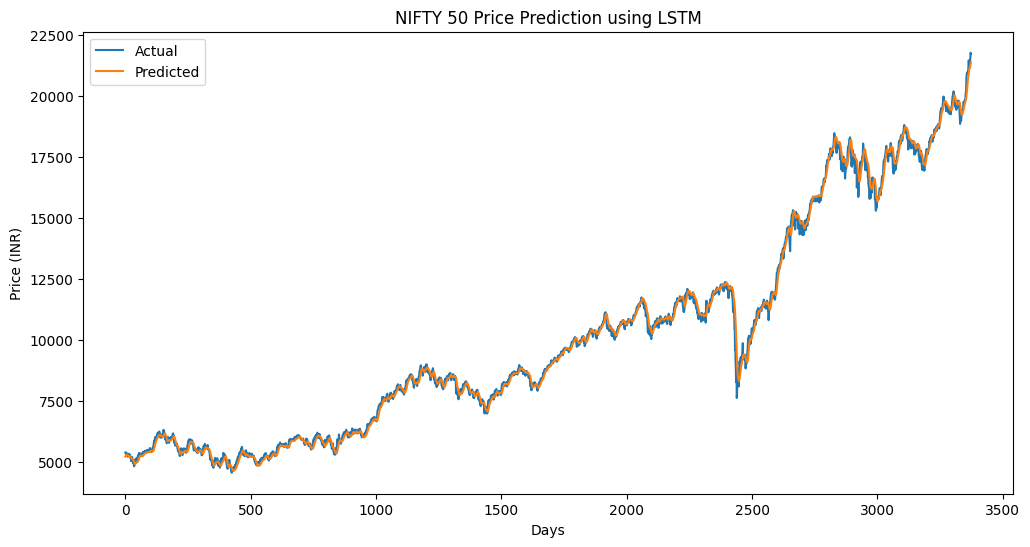

In [1]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

df = yf.download(
    "^NSEI",
    start="2010-01-01",
    end="2024-01-01",
    auto_adjust=True
)

if df.empty:
    raise ValueError("No stock data downloaded. Check your internet connection.")

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df[['Close']].dropna()

if len(df) <= 60:
    raise ValueError("Insufficient stock data for prediction.")

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df)

def create_sequences(data, seq_length):
    X, y = [], []

    for i in range(seq_length, len(data)):
        X.append(data[i - seq_length:i, 0])
        y.append(data[i, 0])

    return np.array(X), np.array(y)

seq_length = 60

X, y = create_sequences(scaled_data, seq_length)

X = np.reshape(X, (X.shape[0], X.shape[1], 1))

model = Sequential()

model.add(LSTM(
    units=50,
    return_sequences=True,
    input_shape=(X.shape[1], 1)
))

model.add(Dropout(0.2))

model.add(LSTM(
    units=50,
    return_sequences=False
))

model.add(Dropout(0.2))

model.add(Dense(units=1))

model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

model.summary()

history = model.fit(
    X,
    y,
    epochs=20,
    batch_size=32
)

last_sequence = scaled_data[-seq_length:]

last_sequence = np.reshape(
    last_sequence,
    (1, seq_length, 1)
)

predicted_price = model.predict(last_sequence)

predicted_price = scaler.inverse_transform(predicted_price)

print(
    f"Predicted Next Day Closing Price: ₹{predicted_price[0][0]:.2f}"
)

train_predict = model.predict(X)

train_predict = scaler.inverse_transform(train_predict)

y_actual = scaler.inverse_transform(
    y.reshape(-1, 1)
)

plt.figure(figsize=(12, 6))

plt.plot(y_actual, label='Actual')

plt.plot(train_predict, label='Predicted')

plt.title('NIFTY 50 Price Prediction using LSTM')

plt.xlabel('Days')

plt.ylabel('Price (INR)')

plt.legend()

plt.show()
